# Qalaisyn 🇰🇿 — making AI understand Kazakh the way people actually text

**Track:** AI + Languages · **Veritas AI International High School Hackathon 2026**

> **AI understands Kazakh only when it is written "properly" — and almost nobody texts that way.**

Most Kazakhs text in Latin letters without the special Kazakh letters: *"qalaisyn"* instead of *"қалайсың"*.
Translation and chatbot models are trained on standard Cyrillic Kazakh, so they lose most of the meaning of
real messages. **Qalaisyn** is a small, fast AI layer that sits in front of any translator or chatbot and turns
chat-style Kazakh back into standard Kazakh.

| Headline result (held-out test data) | |
|---|---|
| Meaning lost when a translator reads chat-style Kazakh | **75%** (chrF 60.8 → 15.3) |
| Meaning recovered by Qalaisyn — everyday sentences | **98%** |
| Meaning recovered by Qalaisyn — news sentences | **97%** |

*This project is a prototype. It is not a product for medical, financial or emergency use.*

**Contents:** 1 · The problem → 2 · Data → 3 · Simulating chat writing → 4 · Models → 5 · Restoration results →
6 · Does the meaning survive? (translation) → 7 · Messy messages (stress tests) → 8 · Where it fails →
9 · Native-speaker check → 10 · Try it → 11 · Limitations, next steps, sources

## 1 · The problem — and who it is for

**User:** Gulnar, 62, from a village in Turkistan region. Her phone has no Kazakh keyboard, so she writes in Latin
letters. One night her grandson has a fever and she texts the clinic's chatbot:

> *balamnyn qyzuy 39 koterildi ne isteu kerek* — "my child's temperature rose to 39, what should I do"

Banks, clinics and e-government services in Kazakhstan increasingly put AI first in line. If the AI cannot read
how people really write, the people who write "the way they text" get worse help — or none.
The same pattern exists for Uzbek, Kyrgyz, Azerbaijani, Turkish, Vietnamese, Yoruba and many other languages whose
special letters get dropped on phones.

**What goes in:** a chat-style Kazakh message. **What comes out:** standard Cyrillic Kazakh that any downstream AI
(translator, chatbot, search) can understand.

In [1]:
# Setup. On Google Colab this downloads everything (≈200 MB); locally it reuses existing files.
import os, sys, json, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
ROOT = Path(".").resolve()
(ROOT / "src").mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
if IN_COLAB:
    subprocess.run("pip -q install sacrebleu pyarrow transformers==4.46.3 sentencepiece", shell=True)
print("Colab:", IN_COLAB, "| working dir:", ROOT)

Colab: False | working dir: C:\Users\zhasb\Projects\Qalaisyn


## 2 · Data

All data is public. Nothing from a test set is used for training.

| Purpose | Dataset | Size |
|---|---|---|
| Training text (language model + vocabulary) | Kazakh Wikipedia (Nov 2023 dump) | 1.5 M sentences |
| Training text, conversational | Tatoeba Kazakh sentences (not in test) | ~4 k sentences |
| **Test 1 — everyday sentences** | Tatoeba Kazakh–English pairs | 623 sentences |
| **Test 2 — news sentences** | FLORES-200 `devtest` (Kazakh + professional English) | 1,012 sentences (300 for translation) |
| Tuning only | FLORES-200 `dev` | 997 sentences |
| Native-speaker test | messages written and corrected by our team member | see section 9 |

In [2]:
%%writefile src/chatify.py
"""chatify: turn standard Cyrillic Kazakh into realistic chat-style Latin Kazakh.

Each simulated writer has a *profile* of typing habits (how they write қ, ә, ш ...).
This is how we create training/test pairs without collecting anyone's private messages.
"""
import random
import re

# For every Cyrillic letter: list of (latin_spelling, weight) per profile.
# Profiles:
#   careful   - uses q, ä, ö, ü, ğ, ñ (close to the official Latin alphabet)
#   typical   - q for қ, but drops other special letters (most common in chats)
#   minimal   - only plain ASCII, no q (k for both к and қ)
#   mixed     - typical + random variation between habits inside one message
BASE = {
    "а": "a", "б": "b", "в": "v", "г": "g", "д": "d", "е": "e", "ё": "yo",
    "ж": "zh", "з": "z", "и": "i", "й": "i", "к": "k", "л": "l", "м": "m",
    "н": "n", "о": "o", "п": "p", "р": "r", "с": "s", "т": "t", "у": "u",
    "ф": "f", "х": "h", "ц": "ts", "ч": "ch", "ш": "sh", "щ": "sh", "ъ": "",
    "ы": "y", "ь": "", "э": "e", "ю": "yu", "я": "ya",
    "ә": "a", "ғ": "g", "қ": "k", "ң": "n", "ө": "o", "ұ": "u", "ү": "u",
    "һ": "h", "і": "i",
}

# Options per letter for each profile: list of (spelling, probability).
PROFILES = {
    "careful": {
        "қ": [("q", 1.0)], "ә": [("ä", 0.8), ("a", 0.2)], "ө": [("ö", 0.8), ("o", 0.2)],
        "ү": [("ü", 0.8), ("u", 0.2)], "ұ": [("u", 1.0)], "ғ": [("ğ", 0.5), ("g", 0.5)],
        "ң": [("ñ", 0.4), ("ng", 0.3), ("n", 0.3)], "і": [("i", 1.0)], "ы": [("y", 0.8), ("ı", 0.2)],
        "ш": [("sh", 0.7), ("ş", 0.3)], "ж": [("zh", 0.5), ("j", 0.5)], "х": [("h", 0.5), ("x", 0.5)],
        "й": [("i", 0.5), ("y", 0.5)], "у": [("u", 0.8), ("w", 0.2)], "ч": [("ch", 1.0)],
    },
    "typical": {
        "қ": [("q", 0.85), ("k", 0.15)], "ә": [("a", 0.9), ("ä", 0.1)], "ө": [("o", 1.0)],
        "ү": [("u", 1.0)], "ұ": [("u", 1.0)], "ғ": [("g", 0.85), ("gh", 0.15)],
        "ң": [("n", 0.7), ("ng", 0.3)], "і": [("i", 1.0)], "ы": [("y", 0.7), ("i", 0.3)],
        "ш": [("sh", 0.75), ("w", 0.25)], "ж": [("zh", 0.4), ("j", 0.6)], "х": [("h", 0.5), ("x", 0.5)],
        "й": [("i", 0.6), ("y", 0.4)], "у": [("u", 0.85), ("w", 0.15)], "ч": [("ch", 1.0)],
    },
    "minimal": {
        "қ": [("k", 1.0)], "ә": [("a", 1.0)], "ө": [("o", 1.0)], "ү": [("u", 1.0)],
        "ұ": [("u", 1.0)], "ғ": [("g", 1.0)], "ң": [("n", 1.0)], "і": [("i", 1.0)],
        "ы": [("i", 0.6), ("y", 0.4)], "ш": [("sh", 0.6), ("w", 0.4)], "ж": [("j", 0.7), ("zh", 0.3)],
        "х": [("h", 0.6), ("x", 0.4)], "й": [("i", 0.7), ("y", 0.3)], "у": [("u", 1.0)], "ч": [("ch", 1.0)],
    },
}
PROFILE_NAMES = ["careful", "typical", "minimal", "mixed"]

_word_re = re.compile(r"[а-яёәғқңөұүһі]+(?:-[а-яёәғқңөұүһі]+)*|\d+", re.IGNORECASE)


def normalize_cyr(text: str) -> str:
    """Gold format: lowercase Cyrillic words and numbers, no punctuation."""
    text = text.lower().replace("ё", "е")
    # common look-alike Latin letters inside Cyrillic text
    text = text.translate(str.maketrans({"i": "і", "a": "а", "o": "о", "e": "е", "c": "с", "p": "р"}))
    return " ".join(_word_re.findall(text))


def _pick(options, rng):
    r = rng.random()
    acc = 0.0
    for spelling, p in options:
        acc += p
        if r <= acc:
            return spelling
    return options[-1][0]


def chatify(text: str, profile: str = "typical", rng: random.Random | None = None) -> str:
    """Convert (already normalized) Cyrillic Kazakh into chat-style Latin."""
    rng = rng or random.Random(0)
    text = normalize_cyr(text)
    out = []
    # a writer keeps the same habit for a letter inside one message (more realistic)
    habits = {}
    for ch in text:
        prof = profile
        if profile == "mixed":
            prof = rng.choice(["careful", "typical", "minimal"])
            habit_key = ch + prof
        else:
            habit_key = ch
        table = PROFILES[prof]
        if ch in table:
            if habit_key not in habits or profile == "mixed":
                habits[habit_key] = _pick(table[ch], rng)
            out.append(habits[habit_key])
        elif ch in BASE:
            out.append(BASE[ch])
        else:
            out.append(ch)
    s = "".join(out)
    # chat noise: occasionally drop a hyphen, double a final letter for emphasis
    if rng.random() < 0.3:
        s = s.replace("-", " ")
    return re.sub(r"\s+", " ", s).strip()


UNSEEN = {"ә": "ae", "ө": "oe", "ү": "ue", "х": "kh", "қ": "kk", "ғ": "gg"}


def add_typos(chat: str, rate: float, rng: random.Random) -> str:
    """Realistic thumb typos: drop, double or swap letters in some words."""
    out = []
    for w in chat.split():
        if len(w) > 3 and not w.isdigit() and rng.random() < rate:
            i = rng.randrange(1, len(w) - 1)
            kind = rng.choice(["drop", "double", "swap"])
            if kind == "drop":
                w = w[:i] + w[i + 1:]
            elif kind == "double":
                w = w[:i] + w[i] + w[i:]
            else:
                w = w[:i] + w[i + 1] + w[i] + w[i + 2:]
        out.append(w)
    return " ".join(out)


def chatify_unseen(text: str, rng: random.Random) -> str:
    """A writer with habits the model was never told about (ae for ә, kh for х, kk for қ ...)."""
    text = normalize_cyr(text)
    s = "".join(UNSEEN.get(ch, PROFILES["minimal"].get(ch, [(BASE.get(ch, ch), 1)])[0][0]) for ch in text)
    return re.sub(r"\s+", " ", s).strip()


if __name__ == "__main__":
    demo = "Баламның қызуы 39 көтерілді, не істеу керек?"
    for p in PROFILE_NAMES:
        print(f"{p:8s} -> {chatify(demo, p, random.Random(1))}")

Overwriting src/chatify.py


In [3]:
%%writefile src/build_data.py
"""Build training corpus and held-out test sets.

Training text : Kazakh Wikipedia + Tatoeba Kazakh sentences (minus test sentences)
Test sets     : FLORES-200 devtest (kaz + professional English), Tatoeba kaz-eng pairs
Tuning set    : FLORES-200 dev
Nothing from a test set is allowed into training.
"""
import bz2
import json
import random
import re
import sys
from pathlib import Path

import pyarrow.parquet as pq

sys.path.insert(0, str(Path(__file__).parent))
from chatify import PROFILE_NAMES, chatify, normalize_cyr  # noqa: E402

ROOT = Path(__file__).resolve().parents[1]
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

CYR = re.compile(r"[а-яёәғқңөұүһі]", re.I)
LAT = re.compile(r"[a-z]", re.I)
SENT_SPLIT = re.compile(r"(?<=[.!?…])\s+|\n+")


def good_sentence(s: str) -> bool:
    n_cyr, n_lat = len(CYR.findall(s)), len(LAT.findall(s))
    words = s.split()
    return 3 <= len(words) <= 40 and n_cyr > 10 * (n_lat + 1) / 2 and n_lat < 3


def read_lines(p):
    return [l.rstrip("\n") for l in open(p, encoding="utf-8")]


def main(max_wiki=1_500_000):
    # ---------------- test sets
    fl = RAW / "flores200_dataset"
    flores_test = list(zip(read_lines(fl / "devtest/kaz_Cyrl.devtest"), read_lines(fl / "devtest/eng_Latn.devtest")))
    flores_dev = list(zip(read_lines(fl / "dev/kaz_Cyrl.dev"), read_lines(fl / "dev/eng_Latn.dev")))

    kaz = {}
    for line in open(RAW / "kaz_sentences.tsv", encoding="utf-8"):
        sid, _, text = line.rstrip("\n").split("\t", 2)
        kaz[sid] = text
    links = [l.split() for l in read_lines(RAW / "kaz-eng_links.tsv")]
    need_eng = {e for _, e in links}
    eng = {}
    with open(RAW / "eng_sentences.tsv", encoding="utf-8") as f:
        for line in f:
            sid, _, text = line.rstrip("\n").split("\t", 2)
            if sid in need_eng:
                eng[sid] = text
    tat_pairs, seen = [], set()
    for k, e in links:
        if k in kaz and e in eng and k not in seen:
            seen.add(k)
            tat_pairs.append((kaz[k], eng[e]))
    tat_test_ids = seen

    test_norm = {normalize_cyr(k) for k, _ in flores_test + flores_dev + tat_pairs}

    # ---------------- training text
    tat_train = [normalize_cyr(t) for sid, t in kaz.items() if sid not in tat_test_ids]
    tat_train = [s for s in tat_train if s and s not in test_norm]

    wiki, wseen = [], set()
    pf = pq.ParquetFile(RAW / "kkwiki.parquet")
    for batch in pf.iter_batches(columns=["text"], batch_size=2000):
        for doc in batch.column(0).to_pylist():
            for s in SENT_SPLIT.split(doc):
                s = s.strip()
                if not good_sentence(s):
                    continue
                n = normalize_cyr(s)
                if len(n.split()) < 3 or n in wseen or n in test_norm:
                    continue
                wseen.add(n)
                wiki.append(n)
        if len(wiki) >= max_wiki:
            break
    random.Random(0).shuffle(wiki)

    (OUT / "train_wiki.txt").write_text("\n".join(wiki), encoding="utf-8")
    (OUT / "train_tatoeba.txt").write_text("\n".join(tat_train), encoding="utf-8")

    # ---------------- chat-style versions of the test sets (4 writer profiles)
    def make(pairs, name):
        rows = []
        for i, (k, e) in enumerate(pairs):
            for p in PROFILE_NAMES:
                rng = random.Random(f"{name}-{i}-{p}")
                rows.append({"id": i, "profile": p, "kaz": k, "gold": normalize_cyr(k),
                             "chat": chatify(k, p, rng), "eng": e})
        with open(OUT / f"{name}.jsonl", "w", encoding="utf-8") as f:
            for r in rows:
                f.write(json.dumps(r, ensure_ascii=False) + "\n")
        return rows

    make(flores_test, "test_flores")
    make(tat_pairs, "test_tatoeba")
    make(flores_dev, "dev_flores")
    print(f"wiki sentences: {len(wiki):,}  tatoeba train: {len(tat_train):,}")
    print(f"test: flores {len(flores_test)}, tatoeba {len(tat_pairs)}; dev flores {len(flores_dev)}")


if __name__ == "__main__":
    main()

Overwriting src/build_data.py


In [4]:
# Build the corpus and test sets (downloads raw data on Colab).
RAW = ROOT / "data" / "raw"; RAW.mkdir(parents=True, exist_ok=True)
def get(url, name):
    if not (RAW / name).exists():
        subprocess.run(f'curl -sL -o "{RAW / name}" "{url}"', shell=True, check=True)
get("https://downloads.tatoeba.org/exports/per_language/kaz/kaz_sentences.tsv.bz2", "kaz_sentences.tsv.bz2")
get("https://downloads.tatoeba.org/exports/per_language/eng/eng_sentences.tsv.bz2", "eng_sentences.tsv.bz2")
get("https://downloads.tatoeba.org/exports/per_language/kaz/kaz-eng_links.tsv.bz2", "kaz-eng_links.tsv.bz2")
get("https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz", "flores200.tar.gz")
get("https://huggingface.co/datasets/wikimedia/wikipedia/resolve/main/20231101.kk/train-00000-of-00001.parquet", "kkwiki.parquet")
if not (RAW / "kaz_sentences.tsv").exists():
    subprocess.run(f'cd "{RAW}" && bunzip2 -kf *.bz2 && tar -xzf flores200.tar.gz --wildcards "*kaz_Cyrl*" "*eng_Latn*" "*kir_Cyrl*"', shell=True)
P = ROOT / "data" / "processed"
if not (P / "test_tatoeba.jsonl").exists():
    import build_data; build_data.main()
for n in ["train_wiki.txt", "train_tatoeba.txt"]:
    print(n, sum(1 for _ in open(P / n, encoding="utf-8")), "sentences")
for n in ["test_tatoeba", "test_flores", "dev_flores"]:
    print(n, sum(1 for _ in open(P / f"{n}.jsonl", encoding="utf-8")), "messages (sentences x 4 writing styles)")

train_wiki.txt 1507331 sentences
train_tatoeba.txt 3950 sentences
test_tatoeba 2492 messages (sentences x 4 writing styles)
test_flores 4048 messages (sentences x 4 writing styles)
dev_flores 3988 messages (sentences x 4 writing styles)


## 3 · Simulating how people really type

We cannot use other people's private chats, so we **simulate writers**. Each simulated writer has a profile of
typing habits (how they spell қ, ә, ш …) and keeps the same habit inside one message, like real people do:

* **careful** — close to the official Latin alphabet (q, ä, ö, ü)
* **typical** — q for қ, but drops the other special letters (the most common chat style)
* **minimal** — plain ASCII only, k for both к and қ
* **mixed** — switches habits inside a message

Real messages from a native speaker are tested separately in section 9.

In [5]:
import random
from chatify import chatify, PROFILE_NAMES
for s in ["Баламның қызуы 39 көтерілді, не істеу керек?", "Картадан ақша кетіп қалды, мен ештеңе сатып алған жоқпын."]:
    print(s)
    for p in PROFILE_NAMES:
        print(f"   {p:8s} -> {chatify(s, p, random.Random(3))}")

Баламның қызуы 39 көтерілді, не істеу керек?
   careful  -> balamnyng qyzuy 39 köterildi ne isteu kerek
   typical  -> balamnyn qyzuy 39 koterildi ne isteu kerek
   minimal  -> balamnin kizui 39 koterildi ne isteu kerek
   mixed    -> balamnyng qızuy 39 koterildi ne isteu kerek
Картадан ақша кетіп қалды, мен ештеңе сатып алған жоқпын.
   careful  -> kartadan aqsha ketip qaldy men eshtenge satyp alğan zhoqpyn
   typical  -> kartadan aqsha ketip qaldy men eshtene satyp algan zhoqpyn
   minimal  -> kartadan aksha ketip kaldy men eshtene satyp algan jokpyn
   mixed    -> kartadan aksha ketip qaldy men eshtene satıp alğan jokpyn


## 4 · Models

Restoring the letters is a guessing game that needs context: is `k` **к** or **қ**? is `a` **а** or **ә**? is `i`
**і**, **и** or **ы**? is `n` **н** or **ң**? We compare five systems, from doing nothing to ours:

| Code | System | Idea |
|---|---|---|
| B0 | *raw chat* | give the chat text to the translator unchanged (size of the problem) |
| B1 | *letter rules* | every Latin letter → its most common Cyrillic letter |
| B2 | *dictionary* | every word → the most frequent Kazakh word that matches its letters (a strong simple baseline) |
| M1 | **Qalaisyn** | candidate words + typing-habit model + **word bigram language model** decoded with **Viterbi** over the whole sentence; unknown words are restored by a **character 5-gram model** |
| M2 | **Qalaisyn + typo search** | M1, plus: if a word is unknown or rare, also consider real words one edit away (symmetric-delete index) |

All settings of M1/M2 were tuned on FLORES `dev` only.

In [6]:
%%writefile src/restore.py
"""Restore standard Cyrillic Kazakh from chat-style Latin Kazakh.

Three restorers, from simplest to ours:
  B1  RuleRestorer        - every Latin letter -> its most common Cyrillic letter
  B2  DictRestorer        - every word -> its most frequent matching Kazakh word
  M1  QalaisynRestorer    - candidate words + typing-habit channel model
                            + word n-gram language model (Viterbi over the sentence)
                            + character n-gram model for unknown words
"""
from __future__ import annotations

import math
import re
from collections import Counter, defaultdict

# ---------------------------------------------------------------- canonical keys
# Every Cyrillic letter is reduced to a "skeleton" letter. Words that look the
# same once the special Kazakh letters are stripped share a skeleton.
CANON = {
    "а": "a", "ә": "a", "б": "b", "в": "v", "г": "g", "ғ": "g", "д": "d", "е": "e",
    "э": "e", "ж": "j", "з": "z", "и": "i", "й": "i", "і": "i", "ы": "i", "к": "k",
    "қ": "k", "л": "l", "м": "m", "н": "n", "ң": "n", "о": "o", "ө": "o", "п": "p",
    "р": "r", "с": "s", "т": "t", "у": "u", "ұ": "u", "ү": "u", "ф": "f", "х": "h",
    "һ": "h", "ц": "c", "ч": "C", "ш": "S", "щ": "S", "ъ": "", "ь": "", "ю": "iu",
    "я": "ia", "ё": "io", "-": "-",
}


def canon_word(word: str) -> str:
    return "".join(CANON.get(ch, ch) for ch in word)


# Chat-side parsing: each position may be read in several ways.
_MULTI = [
    ("sh", ["S"]), ("zh", ["j"]), ("ch", ["C"]), ("gh", ["g"]),
    ("ts", ["c", "ts"]), ("ng", ["n", "ng"]),
]
_SINGLE = {
    "q": ["k"], "ä": ["a"], "ö": ["o"], "ü": ["u"], "ı": ["i"], "y": ["i"],
    "ğ": ["g"], "ñ": ["n"], "ş": ["S"], "x": ["h"], "w": ["S", "u", "v"],
    "c": ["c", "C", "s"], "j": ["j"],
}
# Latin markers that can only come from one special Kazakh letter.
STRICT = {"q": "қ", "ä": "ә", "ö": "ө", "ü": "ү", "ğ": "ғ", "ñ": "ң", "ı": "ы", "ş": "ш"}


def clean_token(tok: str) -> str:
    return re.sub(r"['`’]", "", tok.lower())


def chat_variants(tok: str, limit: int = 32) -> list[str]:
    tok = clean_token(tok)
    results = [""]
    i = 0
    while i < len(tok):
        opts = None
        for pat, outs in _MULTI:
            if tok.startswith(pat, i):
                opts, step = outs, len(pat)
                break
        if opts is None:
            ch = tok[i]
            opts, step = _SINGLE.get(ch, [ch]), 1
        results = [r + o for r in results for o in opts][:limit]
        i += step
    return results


# ---------------------------------------------------------------- B1: rules
RULE_MULTI = [("sh", "ш"), ("zh", "ж"), ("ch", "ч"), ("gh", "ғ"), ("ts", "ц"),
              ("yu", "ю"), ("ya", "я"), ("yo", "ё"), ("ng", "ң")]
RULE_SINGLE = {
    "a": "а", "b": "б", "c": "ц", "d": "д", "e": "е", "f": "ф", "g": "г", "h": "х",
    "i": "і", "j": "ж", "k": "к", "l": "л", "m": "м", "n": "н", "o": "о", "p": "п",
    "q": "қ", "r": "р", "s": "с", "t": "т", "u": "у", "v": "в", "w": "у", "x": "х",
    "y": "ы", "z": "з", "ä": "ә", "ö": "ө", "ü": "ү", "ğ": "ғ", "ñ": "ң", "ı": "ы", "ş": "ш",
}


def rule_word(tok: str) -> str:
    tok = clean_token(tok)
    if tok.isdigit():
        return tok
    out, i = [], 0
    while i < len(tok):
        for pat, cyr in RULE_MULTI:
            if tok.startswith(pat, i):
                out.append(cyr)
                i += len(pat)
                break
        else:
            out.append(RULE_SINGLE.get(tok[i], tok[i]))
            i += 1
    return "".join(out)


class RuleRestorer:
    name = "B1 rules"

    def restore(self, text: str) -> str:
        return " ".join(rule_word(t) for t in text.split())


# ---------------------------------------------------------------- shared lexicon
def strict_ok(tok: str, word: str) -> bool:
    """A chat token with 'q' must come from a word with at least that many 'қ', etc."""
    t = clean_token(tok)
    for lat, cyr in STRICT.items():
        if t.count(lat) > word.count(cyr):
            return False
    return True


class Lexicon:
    def __init__(self):
        self.uni = Counter()
        self.bi = Counter()
        self.ctx = Counter()           # number of tokens following a word
        self.followers = Counter()     # distinct followers (Witten-Bell)
        self.by_key = defaultdict(list)
        self.total = 0
        self.char = None

    def fit(self, sentences, weights=None):
        weights = weights or [1] * len(sentences)
        for sent, w in zip(sentences, weights):
            words = ["<s>"] + sent.split() + ["</s>"]
            for a, b in zip(words, words[1:]):
                self.uni[b] += w
                if self.bi[(a, b)] == 0:
                    self.followers[a] += 1
                self.bi[(a, b)] += w
                self.ctx[a] += w
        self.total = sum(self.uni.values())
        for word, c in self.uni.items():
            if word in ("</s>",) or word.isdigit():
                continue
            self.by_key[canon_word(word)].append((c, word))
        for k in self.by_key:
            self.by_key[k].sort(reverse=True)
        self.char = CharLM(order=5).fit(self.uni)
        return self

    def p_uni(self, w):
        return (self.uni.get(w, 0) + 0.1) / (self.total + 0.1 * (len(self.uni) + 1))

    def logp(self, w, prev):
        """Interpolated bigram (Witten-Bell)."""
        pu = self.p_uni(w)
        c_prev = self.ctx.get(prev, 0)
        if c_prev == 0:
            return math.log(pu)
        t = self.followers[prev]
        lam = c_prev / (c_prev + t)
        return math.log(lam * self.bi.get((prev, w), 0) / c_prev + (1 - lam) * pu)

    def candidates(self, tok, top=25):
        seen = {}
        for key in chat_variants(tok):
            for c, w in self.by_key.get(key, [])[:top]:
                if strict_ok(tok, w):
                    seen[w] = max(seen.get(w, 0), c)
        return sorted(seen, key=seen.get, reverse=True)[:top]

    # ---- typo tolerance: words one edit away (symmetric-delete index)
    def build_fuzzy(self, min_count=3):
        self.del_index = defaultdict(set)
        for key, lst in self.by_key.items():
            if lst[0][0] < min_count or len(key) < 4:
                continue
            for i in range(len(key)):
                self.del_index[key[:i] + key[i + 1:]].add(key)
        return self

    def fuzzy_candidates(self, tok, top=10):
        if not hasattr(self, "del_index"):
            return []
        found = {}
        for v in chat_variants(tok, limit=8):
            if len(v) < 4:
                continue
            dels = {v[:i] + v[i + 1:] for i in range(len(v))}
            keys = set(self.del_index.get(v, ()))            # input lost a letter
            for d in dels:
                if d in self.by_key:                          # input has an extra letter
                    keys.add(d)
                keys |= self.del_index.get(d, set())          # swapped / substituted letter
            keys.discard(v)
            for k in keys:
                for c, w in self.by_key[k][:3]:
                    if strict_ok(tok, w):
                        found[w] = max(found.get(w, 0), c)
        return sorted(found, key=found.get, reverse=True)[:top]


# ---------------------------------------------------------------- character LM
# Which Cyrillic letters a skeleton letter can stand for.
CHAR_OPTS = {
    "a": "аә", "k": "кқ", "o": "оө", "u": "уұү", "i": "іиыйю", "n": "нң", "g": "гғ",
    "h": "хһ", "e": "еэ", "S": "шщ", "j": "ж", "C": "ч", "c": "цс", "b": "б", "v": "в",
    "d": "д", "z": "з", "l": "л", "m": "м", "p": "п", "r": "р", "s": "с", "t": "т",
    "f": "ф", "-": "-",
}
STRICT_SKEL = {"q": "қ", "ä": "ә", "ö": "ө", "ü": "ү", "ğ": "ғ", "ñ": "ң", "ı": "ы", "ş": "ш"}


class CharLM:
    def __init__(self, order=5):
        self.n = order
        self.counts = Counter()
        self.ctx = Counter()

    def fit(self, word_counts):
        for w, c in word_counts.items():
            if not w or w in ("<s>", "</s>") or w.isdigit():
                continue
            s = "^" * (self.n - 1) + w + "$"
            for i in range(self.n - 1, len(s)):
                for k in range(1, self.n + 1):
                    gram = s[i - k + 1:i + 1]
                    self.counts[gram] += c
                    self.ctx[gram[:-1]] += c
        return self

    def logp(self, history, ch):
        """Stupid backoff, good enough for ranking."""
        alpha = 0.0
        for k in range(self.n - 1, -1, -1):
            h = history[-k:] if k else ""
            c = self.counts.get(h + ch, 0)
            if c:
                return alpha + math.log(c / self.ctx[h])
            alpha += math.log(0.4)
        return alpha + math.log(1e-6)

    def restore(self, tok, beam=16):
        t = clean_token(tok)
        # parse into slots, each slot = list of cyrillic options (may be multi-char)
        slots, i = [], 0
        while i < len(t):
            two = t[i:i + 2]
            if two in ("sh", "zh", "ch", "gh"):
                slots.append({"sh": ["ш"], "zh": ["ж"], "ch": ["ч"], "gh": ["ғ"]}[two])
                i += 2
                continue
            if two in ("yu", "iu"):
                slots.append(["ю", "иу", "ыу", "йу", "іу"])
                i += 2
                continue
            if two in ("ya", "ia"):
                slots.append(["я", "иа", "ыа", "йа"])
                i += 2
                continue
            if two == "ng":
                slots.append(["ң", "нг"])
                i += 2
                continue
            ch = t[i]
            if ch in STRICT_SKEL:
                slots.append([STRICT_SKEL[ch]])
            elif ch == "y":
                slots.append(["ы", "й", "и"])
            elif ch == "w":
                slots.append(["ш", "у"])
            elif ch == "x":
                slots.append(["х", "һ"])
            elif ch in CHAR_OPTS:
                slots.append(list(CHAR_OPTS[ch]))
            else:
                slots.append([ch])
            i += 1
        hyps = [("^" * (self.n - 1), 0.0)]
        for opts in slots:
            new = []
            for h, s in hyps:
                for o in opts:
                    sc, hh = s, h
                    for c in o:
                        sc += self.logp(hh, c)
                        hh += c
                    new.append((hh, sc))
            new.sort(key=lambda x: -x[1])
            hyps = new[:beam]
        best = max(hyps, key=lambda x: x[1] + self.logp(x[0], "$"))
        return best[0][self.n - 1:]


# ---------------------------------------------------------------- B2: dictionary
class DictRestorer:
    name = "B2 dictionary"

    def __init__(self, lex: Lexicon):
        self.lex = lex

    def restore(self, text: str) -> str:
        out = []
        for tok in text.split():
            if tok.isdigit():
                out.append(tok)
                continue
            cands = self.lex.candidates(tok, top=1)
            out.append(cands[0] if cands else rule_word(tok))
        return " ".join(out)


# ---------------------------------------------------------------- M1: Qalaisyn
class QalaisynRestorer:
    name = "M1 Qalaisyn"

    def __init__(self, lex: Lexicon, habit_penalty=math.log(0.1), oov_penalty=-12.0,
                 top=25, use_char=True, fuzzy=False, typo_penalty=math.log(0.002),
                 name=None, fuzzy_below=5, char_bonus=0.0):
        # defaults for fuzzy_below / typo_penalty / char_bonus were tuned on FLORES dev only
        self.char_bonus = char_bonus
        self.fuzzy_below = fuzzy_below   # look for typo neighbours only if the word is unknown/rare
        self.lex = lex
        self.habit_penalty = habit_penalty
        self.oov_penalty = oov_penalty
        self.top = top
        self.use_char = use_char
        self.fuzzy = fuzzy
        self.typo_penalty = typo_penalty
        if name:
            self.name = name
        if fuzzy and not hasattr(lex, "del_index"):
            lex.build_fuzzy()

    def _channel(self, tok, word, uses_q):
        """Typing-habit model: if this writer uses 'q' for қ, a plain 'k' is probably к."""
        if not uses_q:
            return 0.0
        t = clean_token(tok)
        extra_q = word.count("қ") - t.count("q")
        return self.habit_penalty * max(0, extra_q)

    def restore(self, text: str, explain: bool = False):
        toks = text.split()
        if not toks:
            return ""
        uses_q = "q" in text.lower()
        lattice = []
        for tok in toks:
            if tok.isdigit():
                lattice.append([(tok, 0.0)])
                continue
            cands = self.lex.candidates(tok, self.top)
            opts = [(w, self._channel(tok, w, uses_q)) for w in cands]
            best_count = self.lex.uni.get(cands[0], 0) if cands else 0
            if self.fuzzy and len(tok) >= 4 and best_count < self.fuzzy_below:
                have = set(cands)
                fz = [w for w in self.lex.fuzzy_candidates(tok) if w not in have]
                for w in fz:
                    opts.append((w, self.typo_penalty + self._channel(tok, w, uses_q)))
                if fz and not cands:
                    # keep the letter-by-letter guess in the race (rare names, new words)
                    opts.append((self.lex.char.restore(tok), self.char_bonus))
            if not opts:
                guess = self.lex.char.restore(tok) if self.use_char else rule_word(tok)
                opts = [(guess, self.oov_penalty)]
            lattice.append(opts)
        # Viterbi over candidate words with the bigram LM
        best = {"<s>": (0.0, [])}
        for opts in lattice:
            new = {}
            for w, ch_score in opts:
                cand_best = None
                for prev, (s, path) in best.items():
                    sc = s + ch_score + self.lex.logp(w, prev)
                    if cand_best is None or sc > cand_best[0]:
                        cand_best = (sc, path + [w])
                new[w] = cand_best
            best = new
        final = max(best.items(), key=lambda kv: kv[1][0] + self.lex.logp("</s>", kv[0]))
        words = final[1][1]
        return " ".join(words)

Overwriting src/restore.py


In [7]:
%%writefile src/eval_restore.py
"""Train the lexicon/LM and measure restoration quality (word error rate, char error rate)."""
import json
import pickle
import sys
import time
from collections import defaultdict
from pathlib import Path

sys.path.insert(0, str(Path(__file__).parent))
from restore import DictRestorer, Lexicon, QalaisynRestorer, RuleRestorer  # noqa: E402

ROOT = Path(__file__).resolve().parents[1]
P = ROOT / "data" / "processed"
CACHE = ROOT / "data" / "lexicon.pkl"


def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        cur = [i]
        for j, y in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (x != y)))
        prev = cur
    return prev[-1]


def wer(hyp, ref):
    r = ref.split()
    return edit_distance(hyp.split(), r), len(r)


def cer(hyp, ref):
    return edit_distance(hyp, ref), len(ref)


def load_lexicon(max_wiki=None, tatoeba_weight=20):
    if CACHE.exists() and max_wiki is None:
        with open(CACHE, "rb") as f:
            return pickle.load(f)
    t = time.time()
    wiki = (P / "train_wiki.txt").read_text(encoding="utf-8").split("\n")
    if max_wiki:
        wiki = wiki[:max_wiki]
    tat = (P / "train_tatoeba.txt").read_text(encoding="utf-8").split("\n")
    lex = Lexicon().fit(wiki + tat, [1] * len(wiki) + [tatoeba_weight] * len(tat))
    print(f"lexicon: {len(lex.uni):,} words, {len(lex.bi):,} bigrams, {time.time() - t:.0f}s")
    if max_wiki is None:
        with open(CACHE, "wb") as f:
            pickle.dump(lex, f, protocol=pickle.HIGHEST_PROTOCOL)
    return lex


def load(name):
    return [json.loads(l) for l in open(P / f"{name}.jsonl", encoding="utf-8")]


def evaluate(restorers, rows, out_name=None):
    stats = defaultdict(lambda: [0, 0, 0, 0])
    outputs = []
    for r in rows:
        rec = dict(r)
        for res in restorers + ["B0 raw chat"]:
            name = res if isinstance(res, str) else res.name
            hyp = r["chat"] if isinstance(res, str) else res.restore(r["chat"])
            rec[name] = hyp
            we, wn = wer(hyp, r["gold"])
            ce, cn = cer(hyp, r["gold"])
            for key in (name, f"{name}|{r['profile']}"):
                s = stats[key]
                s[0] += we; s[1] += wn; s[2] += ce; s[3] += cn
        outputs.append(rec)
    if out_name:
        with open(P / f"restored_{out_name}.jsonl", "w", encoding="utf-8") as f:
            for o in outputs:
                f.write(json.dumps(o, ensure_ascii=False) + "\n")
    table = {k: {"WER": v[0] / v[1], "CER": v[2] / v[3]} for k, v in stats.items()}
    return table, outputs


if __name__ == "__main__":
    lex = load_lexicon()
    restorers = [RuleRestorer(), DictRestorer(lex), QalaisynRestorer(lex),
                 QalaisynRestorer(lex, fuzzy=True, name="M2 Qalaisyn+typos")]
    which = sys.argv[1] if len(sys.argv) > 1 else "dev_flores"
    rows = load(which)
    t = time.time()
    table, _ = evaluate(restorers, rows, which)
    print(f"{which}: {len(rows)} messages, {time.time() - t:.0f}s")
    for k in sorted(table):
        if "|" not in k:
            print(f"  {k:16s} WER {table[k]['WER']:.3f}  CER {table[k]['CER']:.3f}")
    for k in sorted(table):
        if "|" in k:
            print(f"  {k:28s} WER {table[k]['WER']:.3f}")

Overwriting src/eval_restore.py


In [8]:
import time
from eval_restore import load_lexicon, load, evaluate
from restore import RuleRestorer, DictRestorer, QalaisynRestorer
t0 = time.time()
lex = load_lexicon()           # trains on 1.5 M sentences (cached after the first run)
lex.build_fuzzy()
print(f"vocabulary {len(lex.uni):,} words · {len(lex.bi):,} word pairs · {time.time()-t0:.0f}s")
RESTORERS = [RuleRestorer(), DictRestorer(lex), QalaisynRestorer(lex),
             QalaisynRestorer(lex, fuzzy=True, name="M2 Qalaisyn+typos")]
msg = "balamnyn qyzuy 39 koterildi ne isteu kerek"
for r in RESTORERS:
    print(f"{r.name:18s} {r.restore(msg)}")

vocabulary 824,407 words · 7,091,928 word pairs · 12s
B1 rules           баламнын қызуы 39 котерілді не істеу керек
B2 dictionary      баламның қызуы 39 көтерілді не істеу керек
M1 Qalaisyn        баламның қызуы 39 көтерілді не істеу керек
M2 Qalaisyn+typos  баламның қызуы 39 көтерілді не істеу керек


## 5 · Restoration results (held-out test sets)

**WER** = share of words restored wrongly, **CER** = share of letters restored wrongly (lower is better).

In [9]:
import pandas as pd
tables = {}
for name in ["test_tatoeba", "test_flores"]:
    tab, _ = evaluate(RESTORERS, load(name), name)
    tables[name] = tab
    df = pd.DataFrame({k: v for k, v in tab.items() if "|" not in k}).T.sort_index()
    print(f"\n{name}"); display(df.style.format("{:.1%}"))


test_tatoeba


,WER,CER
B0 raw chat,99.9%,89.5%
B1 rules,47.6%,10.8%
B2 dictionary,5.4%,1.4%
M1 Qalaisyn,2.3%,0.4%
M2 Qalaisyn+typos,3.8%,0.8%



test_flores


,WER,CER
B0 raw chat,98.3%,89.2%
B1 rules,54.8%,10.6%
B2 dictionary,4.0%,0.8%
M1 Qalaisyn,2.2%,0.4%
M2 Qalaisyn+typos,3.0%,0.6%


In [10]:
# Results broken down by writing style (the brief asks for per-group results)
rows = []
for name, tab in tables.items():
    for k, v in tab.items():
        if "|" in k:
            m, prof = k.split("|"); rows.append({"test": name, "model": m, "style": prof, "WER": v["WER"]})
display(pd.DataFrame(rows).pivot_table(index=["test", "model"], columns="style", values="WER").style.format("{:.1%}"))

## 6 · Does the meaning survive? Translation test

The real question is not letters but **meaning**. We translate every version into English with Meta's free
**NLLB-200** model (`facebook/nllb-200-distilled-600M`) and compare with the **professional English translation**
using **chrF** (higher is better). *Proper Kazakh text* is the ceiling.

`recovered = (system − raw chat) / (proper text − raw chat)`

In [11]:
%%writefile src/eval_translate.py
"""Does the meaning survive? Translate every version with NLLB-200 and score chrF
against the professional English translation."""
import json
import sys
from collections import defaultdict
from pathlib import Path

import sacrebleu
import torch
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

ROOT = Path(__file__).resolve().parents[1]
P = ROOT / "data" / "processed"
CACHE = ROOT / "data" / "translation_cache.jsonl"
MODEL = "facebook/nllb-200-distilled-600M"
CONDITIONS = ["gold", "B0 raw chat", "B1 rules", "B2 dictionary", "M1 Qalaisyn", "M2 Qalaisyn+typos"]


class Translator:
    def __init__(self, src="kaz_Cyrl", tgt="eng_Latn"):
        self.dev = "cuda" if torch.cuda.is_available() else "cpu"
        self.tok = AutoTokenizer.from_pretrained(MODEL, src_lang=src)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(
            MODEL, torch_dtype=torch.float16 if self.dev == "cuda" else torch.float32).to(self.dev).eval()
        self.tgt_id = self.tok.convert_tokens_to_ids(tgt)
        self.cache = {}
        if CACHE.exists():
            for l in open(CACHE, encoding="utf-8"):
                d = json.loads(l)
                self.cache[d["src"]] = d["tgt"]

    @torch.no_grad()
    def translate(self, texts, batch=24):
        todo = sorted({t for t in texts if t not in self.cache}, key=len)
        with open(CACHE, "a", encoding="utf-8") as f:
            for i in range(0, len(todo), batch):
                chunk = todo[i:i + batch]
                enc = self.tok(chunk, return_tensors="pt", padding=True, truncation=True, max_length=200).to(self.dev)
                # English is rarely much longer than the Kazakh source; this also stops
                # the model from rambling on unreadable chat input.
                max_new = min(200, int(enc["input_ids"].shape[1] * 1.5) + 10)
                out = self.model.generate(**enc, forced_bos_token_id=self.tgt_id, max_new_tokens=max_new,
                                          num_beams=1, do_sample=False)
                for s, t in zip(chunk, self.tok.batch_decode(out, skip_special_tokens=True)):
                    self.cache[s] = t
                    f.write(json.dumps({"src": s, "tgt": t}, ensure_ascii=False) + "\n")
                if (i // batch) % 20 == 0:
                    print(f"  translated {i + len(chunk)}/{len(todo)}", flush=True)
        return [self.cache[t] for t in texts]


def score(rows, tr):
    res = {}
    groups = defaultdict(list)
    for r in rows:
        groups["all"].append(r)
        groups[r["profile"]].append(r)
    for cond in CONDITIONS:
        hyps = tr.translate([r[cond] for r in rows])
        for r, h in zip(rows, hyps):
            r[f"en|{cond}"] = h
    for g, rs in groups.items():
        for cond in CONDITIONS:
            res[(g, cond)] = sacrebleu.corpus_chrf([r[f"en|{cond}"] for r in rs], [[r["eng"] for r in rs]]).score
    return res


def main(names):
    tr = Translator()
    summary = {}
    for name in names:
        rows = [json.loads(l) for l in open(P / f"restored_{name}.jsonl", encoding="utf-8")]
        if name.startswith("test_flores"):
            rows = [r for r in rows if r["id"] < 300]   # first 300 sentences x 4 writer profiles
        res = score(rows, tr)
        with open(P / f"translated_{name}.jsonl", "w", encoding="utf-8") as f:
            for r in rows:
                f.write(json.dumps(r, ensure_ascii=False) + "\n")
        print(f"\n== {name} ({len(rows)} messages) chrF ==")
        for g in sorted({gg for gg, _ in res}):
            line = "  ".join(f"{c.split()[0]} {res[(g, c)]:.1f}" for c in CONDITIONS)
            gap = res[(g, "gold")] - res[(g, "B0 raw chat")]
            rec = (res[(g, "M1 Qalaisyn")] - res[(g, "B0 raw chat")]) / gap if gap else 0
            print(f"  {g:8s} {line}  | recovered {rec:.0%}")
        summary[name] = {f"{g}|{c}": v for (g, c), v in res.items()}
    (ROOT / "results").mkdir(exist_ok=True)
    out = ROOT / "results" / "translation_chrf.json"
    old = json.loads(out.read_text()) if out.exists() else {}
    old.update(summary)
    out.write_text(json.dumps(old, indent=2))


if __name__ == "__main__":
    main(sys.argv[1:] or ["test_tatoeba"])

Overwriting src/eval_translate.py


In [12]:
# Translating ~20k sentences takes a while on a laptop GPU, so the notebook loads the saved scores
# produced by `python src/eval_translate.py ...` (run it to reproduce; translations are cached).
chrf = json.loads(Path("results/translation_chrf.json").read_text())
conds = ["gold", "B0 raw chat", "B1 rules", "B2 dictionary", "M1 Qalaisyn", "M2 Qalaisyn+typos"]
out = []
for name in ["test_tatoeba", "test_flores"]:
    d = chrf[name]
    row = {c: d[f"all|{c}"] for c in conds}
    row["recovered (M2)"] = (row["M2 Qalaisyn+typos"] - row["B0 raw chat"]) / (row["gold"] - row["B0 raw chat"])
    out.append(pd.Series(row, name=name))
display(pd.DataFrame(out).style.format({c: "{:.1f}" for c in conds} | {"recovered (M2)": "{:.0%}"}))

,gold,B0 raw chat,B1 rules,B2 dictionary,M1 Qalaisyn,M2 Qalaisyn+typos,recovered (M2)
test_tatoeba,60.8,15.3,41.5,58.4,60.4,59.9,98%
test_flores,52.7,20.1,39.8,51.9,52.2,51.8,97%


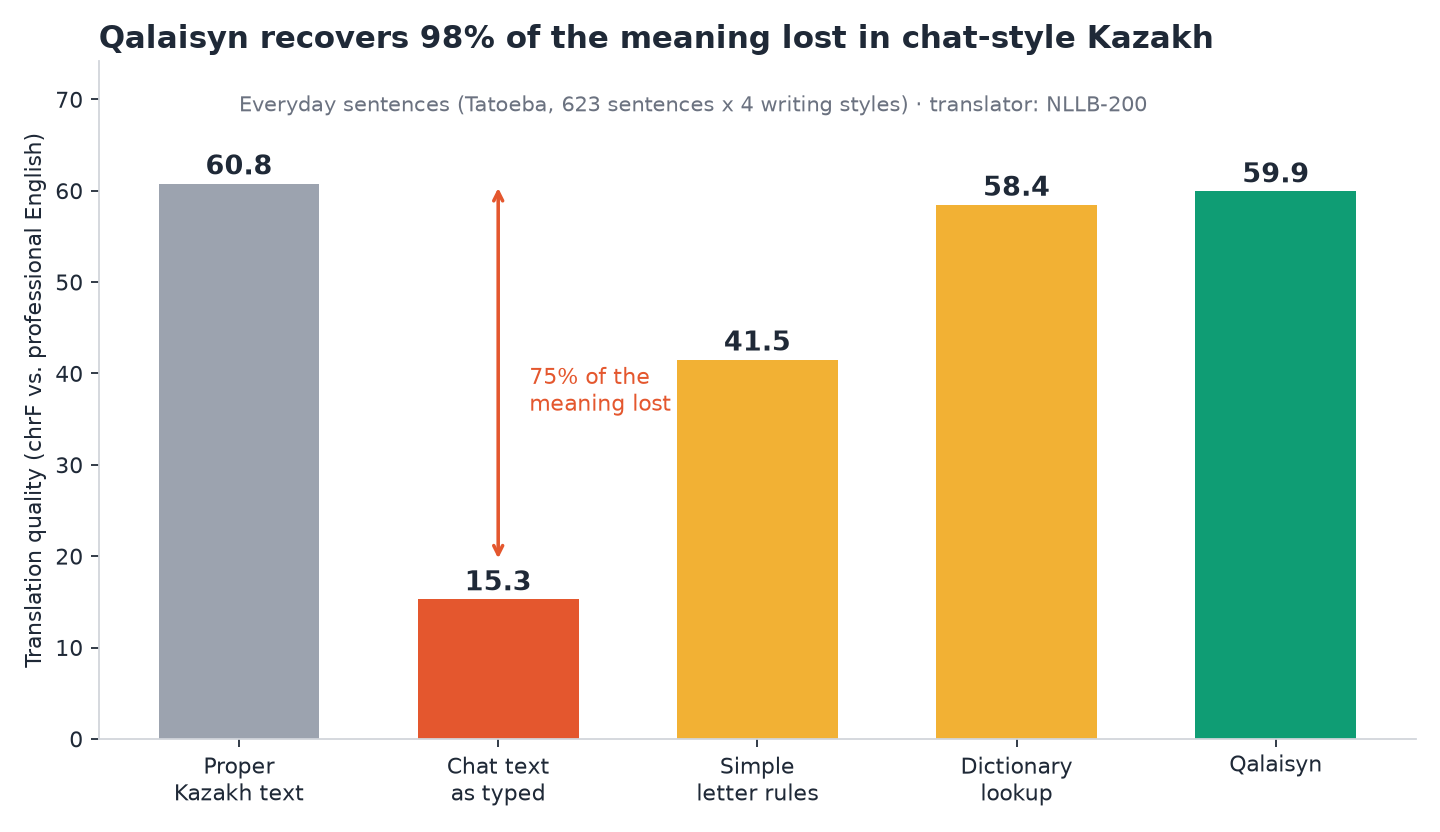

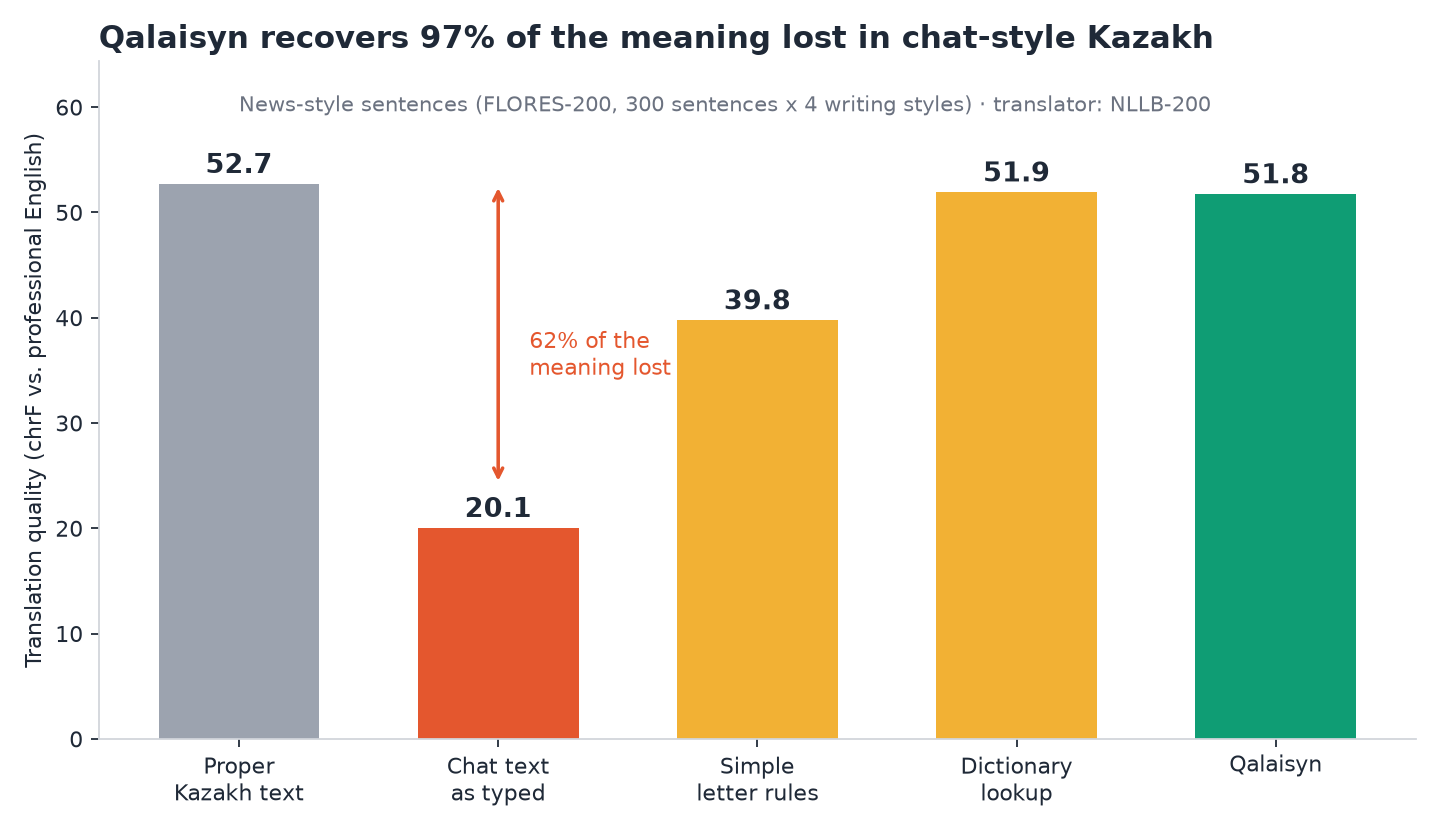

In [13]:
from IPython.display import Image, display
display(Image("figures/main_test_tatoeba.png", width=760))
display(Image("figures/main_test_flores.png", width=760))

In [14]:
# Side by side: what the translator produced before and after Qalaisyn
tr_rows = [json.loads(l) for l in open("data/processed/translated_test_tatoeba.jsonl", encoding="utf-8")]
ex = [r for r in tr_rows if r["profile"] == "typical"][5:13]
display(pd.DataFrame([{"chat message": r["chat"], "translation as typed": r["en|B0 raw chat"],
                       "translation after Qalaisyn": r["en|M2 Qalaisyn+typos"], "professional": r["eng"]} for r in ex]))

,chat message,translation as typed,translation after Qalaisyn,professional
0,zhana zhilinizben,zhana zhilinizben,with your new year,Happy New Year!
1,internet pen telefondi bir jinaqta satil al,internet pen phonedi one in one satil al,Buy the internet and phone in one set,Get both a phone and internet access in a sing...
2,sen metro-da jumys istegin kele me,jumys istegin kele me on the sen metro,do you want to work in the subway,You want to work at METRO?!
3,qosh keldinizder,Qosh Kelinizder,welcome to you,Welcome.
4,sen daretxana,from daretxana,you are toilet,You are a toilet!
5,bizdin kushimiz birlikte,we are working together,our strength is united,Unity is our strength!
6,zhaka kuyylgan en bastysy,zhaka kuyylgan en bastysy,the most important side,Freshness is our top priority.
7,erking ozingde bolsyn,erking ozingde bolsyn,Make your choice,Be yourself!


## 7 · Real messages are messy — stress tests

Our clean simulation could be *too easy*, because the test messages follow the same habits the model knows. So we
asked our own question: **when does Qalaisyn break?**

* **typos-5 / typos-15:** 5% / 15% of words get a thumb typo (dropped, doubled or swapped letter)
* **unseen spellings:** a writer with habits the model was never designed for: `ae` for ә, `oe` for ө, `kh` for х, `kk` for қ

This test exposed a weakness of M1, which led to M2 (typo search). The cost: M2 is slightly worse on perfectly
clean text, but much more robust on messy text. Since real messages are messy, **M2 is our final model.**

In [15]:
%%writefile src/stress.py
"""Stress tests: where does Qalaisyn break?
  typos-5 / typos-15 : 5% / 15% of words get a thumb typo
  unseen-habits      : spellings the model was never designed for (ae, oe, kh, kk)
"""
import json
import random
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).parent))
from chatify import add_typos, chatify, chatify_unseen  # noqa: E402
from eval_restore import evaluate, load, load_lexicon  # noqa: E402
from restore import DictRestorer, QalaisynRestorer, RuleRestorer  # noqa: E402

ROOT = Path(__file__).resolve().parents[1]


def build(rows, kind):
    out = []
    for r in rows:
        if r["profile"] != "typical" and kind != "unseen-habits":
            continue
        if kind == "unseen-habits" and r["profile"] != "minimal":
            continue
        rng = random.Random(f"{kind}-{r['id']}")
        rr = dict(r)
        if kind.startswith("typos"):
            rate = int(kind.split("-")[1]) / 100
            rr["chat"] = add_typos(chatify(r["kaz"], "typical", random.Random(f"t-{r['id']}")), rate, rng)
        else:
            rr["chat"] = chatify_unseen(r["kaz"], rng)
        rr["profile"] = kind
        out.append(rr)
    return out


if __name__ == "__main__":
    name = sys.argv[1] if len(sys.argv) > 1 else "test_tatoeba"
    lex = load_lexicon()
    restorers = [RuleRestorer(), DictRestorer(lex), QalaisynRestorer(lex),
                 QalaisynRestorer(lex, fuzzy=True, name="M2 Qalaisyn+typos")]
    base = load(name)
    results = {}
    for kind in ["typos-5", "typos-15", "unseen-habits"]:
        rows = build(base, kind)
        table, outs = evaluate(restorers, rows, f"{name}_{kind}")
        results[kind] = {k: v for k, v in table.items() if "|" not in k}
        print(kind, "  ".join(f"{k.split()[0]} WER {v['WER']:.3f}" for k, v in sorted(results[kind].items())))
        print("   e.g.", outs[3]["chat"], "->", outs[3]["M1 Qalaisyn"])
    (ROOT / "results").mkdir(exist_ok=True)
    (ROOT / "results" / f"stress_{name}.json").write_text(json.dumps(results, indent=2))

Overwriting src/stress.py


typos-5        e.g. sen metro-da zhumys isteging kele me  ->  сен метро-да жұмыс істегің келе ме


typos-15       e.g. sen metro-da zhumys isteging kele me  ->  сен метро-да жұмыс істегің келе ме


unseen-habits  e.g. sen metro-da jumis istegin kele me  ->  сен метро-да жұмыс істегің келе ме


condition,typos-15,typos-5,unseen-habits
model,,,
B0 raw chat,100.0%,100.0%,99.7%
B1 rules,53.6%,51.1%,63.4%
B2 dictionary,15.7%,9.6%,37.9%
M1 Qalaisyn,12.9%,6.4%,36.7%
M2 Qalaisyn+typos,8.2%,5.6%,13.4%


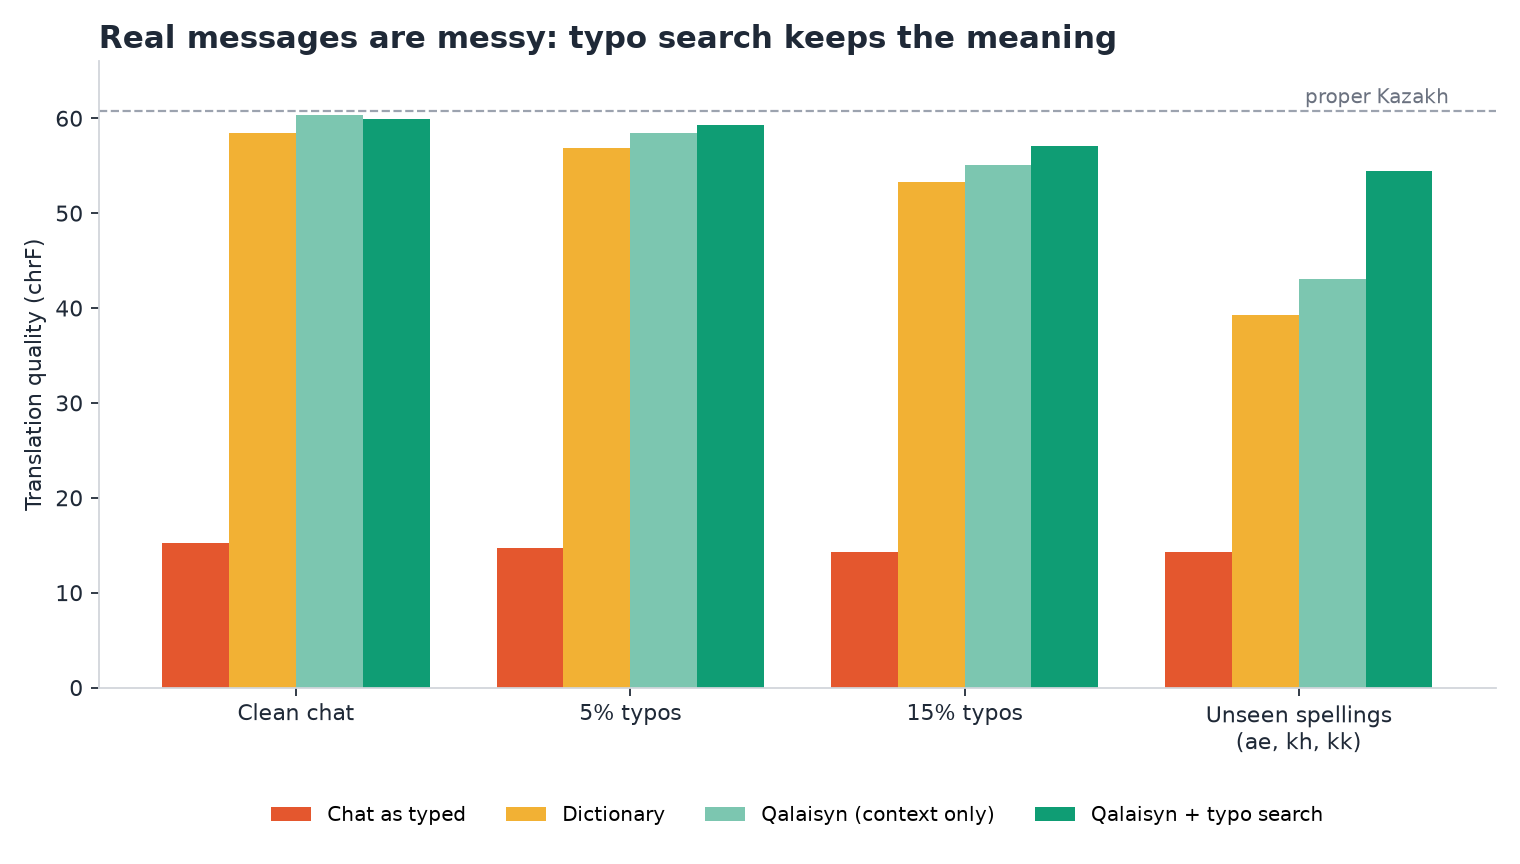

In [16]:
from stress import build
stress_rows = []
for kind in ["typos-5", "typos-15", "unseen-habits"]:
    tab, outs = evaluate(RESTORERS, build(load("test_tatoeba"), kind), f"test_tatoeba_{kind}")
    for k, v in tab.items():
        if "|" not in k: stress_rows.append({"condition": kind, "model": k, "WER": v["WER"]})
    print(f"{kind:14s} e.g. {outs[7]['chat']}  ->  {outs[7]['M2 Qalaisyn+typos']}")
display(pd.DataFrame(stress_rows).pivot(index="model", columns="condition", values="WER").style.format("{:.1%}"))
display(Image("figures/messy_messages.png", width=760))

## 8 · Where it fails, and why

In [17]:
%%writefile src/analysis.py
"""Where does Qalaisyn fail? Per-letter error rates and example failures."""
import json
import sys
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
P = ROOT / "data" / "processed"
MODEL = "M2 Qalaisyn+typos"
LETTERS = "аәкқоөуұүіиыйнңгғхһ"


def rows(name):
    return [json.loads(l) for l in open(P / f"restored_{name}.jsonl", encoding="utf-8")]


def letter_errors(data, model=MODEL):
    tot, err = Counter(), Counter()
    confusions = Counter()
    for r in data:
        g, h = r["gold"].split(), r[model].split()
        if len(g) != len(h):
            continue
        for gw, hw in zip(g, h):
            if len(gw) != len(hw):
                continue
            for a, b in zip(gw, hw):
                if a in LETTERS:
                    tot[a] += 1
                    if a != b:
                        err[a] += 1
                        confusions[(a, b)] += 1
    return {l: (err[l] / tot[l] if tot[l] else 0.0, tot[l]) for l in LETTERS}, confusions


def failures(data, model=MODEL, n=12):
    out = []
    for r in data:
        g, h = r["gold"].split(), r[model].split()
        if len(g) == len(h):
            wrong = [(gw, hw) for gw, hw in zip(g, h) if gw != hw]
            if wrong:
                out.append({"chat": r["chat"], "ours": r[model], "gold": r["gold"], "wrong": wrong,
                            "profile": r["profile"]})
    return out[:n]


def by_length(data, model=MODEL):
    buckets = defaultdict(lambda: [0, 0])
    for r in data:
        n = len(r["gold"].split())
        b = "1-4 words" if n <= 4 else "5-8 words" if n <= 8 else "9-15 words" if n <= 15 else "16+ words"
        g, h = r["gold"].split(), r[model].split()
        e = sum(a != b2 for a, b2 in zip(g, h)) + abs(len(g) - len(h))
        buckets[b][0] += e
        buckets[b][1] += len(g)
    return {k: v[0] / v[1] for k, v in buckets.items()}


if __name__ == "__main__":
    data = rows("test_tatoeba") + rows("test_flores")
    rates, conf = letter_errors(data)
    print("Per-letter error rate (M2, clean test sets):")
    for l, (r, n) in sorted(rates.items(), key=lambda x: -x[1][0]):
        print(f"  {l}: {r:.2%}  (n={n})")
    print("Top confusions:", conf.most_common(10))
    print("By length:", by_length(data))
    for f in failures(rows("test_tatoeba"), n=10):
        print(" ", f["chat"], "|", f["wrong"])
    res = {"letters": {l: {"error_rate": r, "n": n} for l, (r, n) in rates.items()},
           "confusions": [[a, b, c] for (a, b), c in conf.most_common(20)],
           "by_length": by_length(data)}
    (ROOT / "results" / "analysis.json").write_text(json.dumps(res, ensure_ascii=False, indent=2), encoding="utf-8")

Overwriting src/analysis.py


Most common confusions (correct -> ours): [('ң', 'н', 142), ('н', 'ң', 100), ('ы', 'і', 92), ('і', 'ы', 84), ('і', 'и', 75), ('и', 'і', 69), ('а', 'ә', 59), ('қ', 'к', 56)]


Word error rate by message length: {'1-4 words': '4.2%', '16+ words': '6.3%', '5-8 words': '4.5%', '9-15 words': '5.2%'}


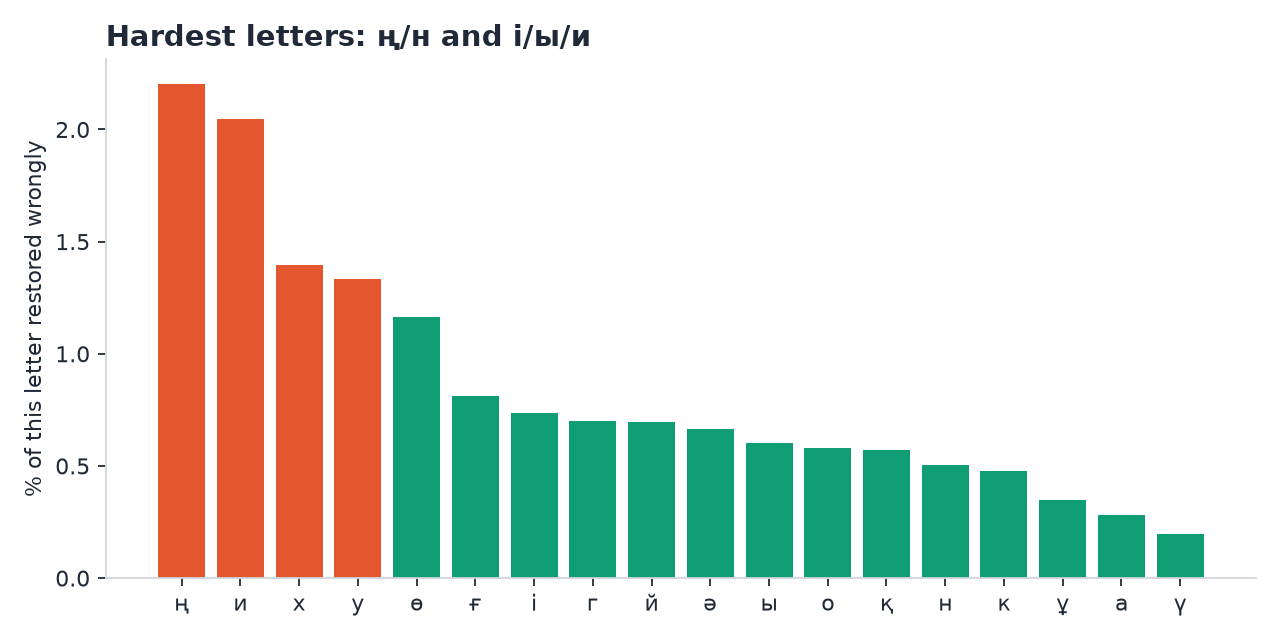

,chat,ours,reference,"wrong words (reference, ours)"
0,almatylıktar balalar üshin meiirimdi qala jasayik,алматылықтар балалар үшін мейірімді қала жасайык,алматылықтар балалар үшін мейірімді қала жасайық,"[(жасайық, жасайык)]"
1,olar bizden barlyq qagaz zhumysty ozine aldy,олар бізден барлық қағаз жұмысты өзіне алды,олар бізден барлық қагаз жұмысты өзіне алды,"[(қагаз, қағаз)]"
2,internet pen telefondi bir jinaqta satil al,интернет пен телефонды бір жинақта сатып ал,интернет пен телефонды бір жинақта сатыл ал,"[(сатыл, сатып)]"
3,erkin ozinde bolsin,еркін өзінде болсын,еркің өзіңде болсын,"[(еркің, еркін), (өзіңде, өзінде)]"
4,men nemis tilin uyrengim keleydi,мен неміс тілін үйренгім келеді,мен неміс тілін үйренгім келейді,"[(келейді, келеді)]"
5,aida awa zhoq,аида ауа жоқ,айда ауа жоқ,"[(айда, аида)]"
6,itter tüni boiy ürdi,иттер түні бойы жүрді,иттер түні бойы үрді,"[(үрді, жүрді)]"
7,ash bala tok balamen oinamaidi,аш бала ток баламен ойнамайды,аш бала тоқ баламен ойнамайды,"[(тоқ, ток)]"
8,qazaq tilin uirenw ushin mening maqsattarim jo...,қазақ тілін үйрену үшін менің мақсаттарым жосп...,қазақ тілін үйрену үшін менің мақсаттарым жосп...,"[(себептерім, себептері)]"
9,rine kop qateler bolatyn wygar,әрине көп қателер болатын шығар,рине көп қателер болатын шығар,"[(рине, әрине)]"


In [18]:
import analysis
data = analysis.rows("test_tatoeba") + analysis.rows("test_flores")
rates, conf = analysis.letter_errors(data)
print("Most common confusions (correct -> ours):", [(a, b, n) for (a, b), n in conf.most_common(8)])
print("Word error rate by message length:", {k: f"{v:.1%}" for k, v in sorted(analysis.by_length(data).items())})
display(Image("figures/letters.png", width=640))
fails = analysis.failures(analysis.rows("test_tatoeba"), n=40)
display(pd.DataFrame([{"chat": x["chat"], "ours": x["ours"], "reference": x["gold"],
                       "wrong words (reference, ours)": x["wrong"]} for x in fails[::4]]))

**What we learned from the failures**

1. **н vs ң and і vs ы vs и** are the hardest letters: these pairs often produce two real words (e.g. *-ның* vs
   *-нің* endings after an ambiguous vowel), so only context can decide, and our bigram context is short.
2. **True ambiguity:** *ot* can be **от** (fire) or **өт** (pass/go) — "Erekshe atap ot!" is a one-word-context case.
3. **Some "errors" are mistakes in the reference.** Tatoeba writes *қагаз* and *сатыл ал*; the correct spellings are
   **қағаз** (paper) and **сатып ал** (buy) — exactly what Qalaisyn produced. Our scores are therefore slightly
   pessimistic.
4. **Unseen spellings** (`kk`, `ae`) are still the weakest condition (≈13–15% word errors), see section 7.

## 9 · Native-speaker check

Our team member (a native Kazakh speaker) wrote real messages exactly the way they text friends, plus the correct
Cyrillic version. These messages were never seen during development.

In [19]:
real = Path("data/real/real_messages.csv")
if real.exists():
    import csv
    rr = [r for r in csv.DictReader(open(real, encoding="utf-8")) if r["how_i_would_text"].strip()]
    rows = [{"id": r["id"], "kaz": r["correct_kazakh_cyrillic"], "chat": r["how_i_would_text"],
             "gold": __import__("chatify").normalize_cyr(r["correct_kazakh_cyrillic"]), "profile": "real",
             "eng": r.get("english", "")} for r in rr]
    tab, outs = evaluate(RESTORERS, rows, "real")
    display(pd.DataFrame({k: v for k, v in tab.items() if "|" not in k}).T.style.format("{:.1%}"))
    display(pd.DataFrame([{"as typed": o["chat"], "Qalaisyn": o["M2 Qalaisyn+typos"], "correct": o["gold"]} for o in outs]))
else:
    print("Native-speaker messages not added yet (data/real/real_messages.csv).")

Native-speaker messages not added yet (data/real/real_messages.csv).


## 10 · Try it

Restore and translate any message. Run `python src/app.py --share` for the interactive Gradio demo (screenshot below).

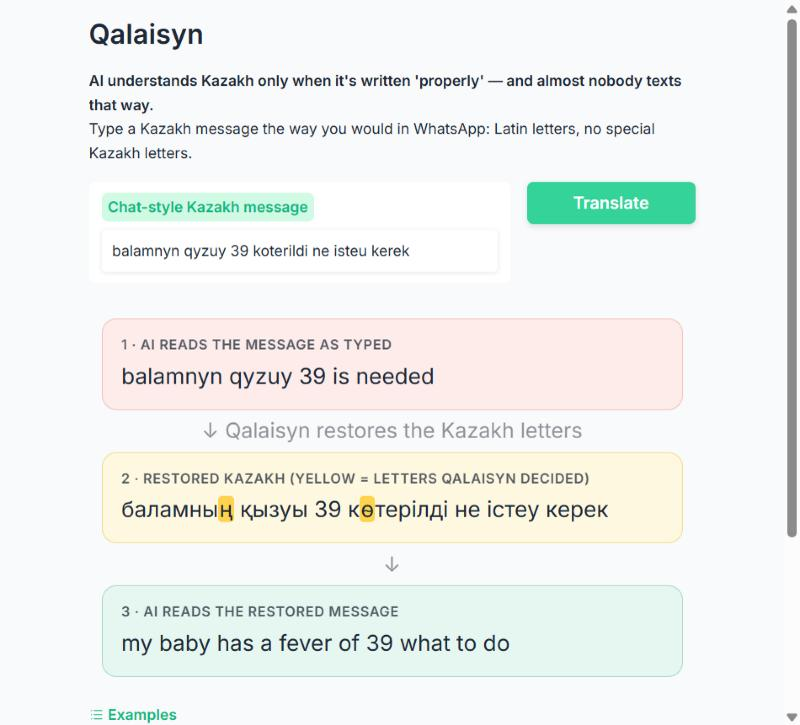

In [20]:
from IPython.display import Image, display
display(Image("figures/demo.jpg", width=620))

In [21]:
import warnings; warnings.filterwarnings("ignore")
from eval_translate import Translator
TR = Translator()
qal = RESTORERS[-1]
for m in ["balamnyn qyzuy 39 koterildi ne isteu kerek",
          "kartadan aqsha ketip qaldy men eshtene satyp algan joqpyn",
          "ajeme jedel jardem kerek uige keliniz"]:
    fixed = qal.restore(m)
    before, after = TR.translate([m, fixed])
    print(f"chat:   {m}\n  AI as typed:  {before}\n  Qalaisyn:     {fixed}\n  AI after:     {after}\n")

chat:   balamnyn qyzuy 39 koterildi ne isteu kerek
  AI as typed:  balamnyn qyzuy 39 is needed
  Qalaisyn:     баламның қызуы 39 көтерілді не істеу керек
  AI after:     my baby has a fever of 39 what to do

chat:   kartadan aqsha ketip qaldy men eshtene satyp algan joqpyn
  AI as typed:  from the card aqsha ketip qaldy men eshtene satyp algan joqpyn
  Qalaisyn:     картадан ақша кетіп қалды мен ештеңе сатып алған жоқпын
  AI after:     I didn 't buy anything .

chat:   ajeme jedel jardem kerek uige keliniz
  AI as typed:  ajeme jedel jardem needed uige keliniz
  Qalaisyn:     әжеме жедел жәрдем керек үйге келіңіз
  AI after:     please come to the house where grandmother needs emergency care



*Note on example 2:* Qalaisyn restored every word correctly, but the translator dropped the first half of the sentence
("money disappeared from my card"). That is a limit of the translation model, not of the restoration — and a reminder
that chrF also measures the translator's own mistakes, which are the same for every system we compare.

## 11 · Limitations, next steps and sources

**Limitations**
* Chat-style test messages are simulated from typing-habit profiles; the native-speaker set is small.
* The language model is trained mostly on Wikipedia, which is more formal than chats.
* Translation quality is measured automatically with chrF on 623 + 300 sentences.
* Russian words written in Latin inside Kazakh messages are not handled yet.

**Next steps**
1. A longer context model (word trigrams or a small neural model) for the н/ң and і/ы/и cases.
2. The same method for Kyrgyz and Uzbek (only the letter table changes), and a plug-in for chatbots of public services.

**Sources and tools**
* Data: [Tatoeba](https://tatoeba.org) (CC BY 2.0 FR) · [FLORES-200](https://github.com/facebookresearch/flores) (CC BY-SA 4.0) ·
  [Kazakh Wikipedia via Hugging Face `wikimedia/wikipedia`](https://huggingface.co/datasets/wikimedia/wikipedia) (CC BY-SA)
* Model: [NLLB-200 distilled 600M](https://huggingface.co/facebook/nllb-200-distilled-600M) (Meta, CC BY-NC 4.0) — used only for evaluation
* Libraries: PyTorch, Hugging Face Transformers, sacrebleu (chrF), pandas, matplotlib, Gradio
* AI tools: Claude (Anthropic) helped write code and text; every part was reviewed and explained to the team.

*This project is a prototype and is not medical or financial advice.*